# HW2 Part 1: Data Cleaning & Validation

**Author:** Nirmit Ghughu

This notebook cleans the deliberately dirty `ohlc_hw` table and saves the result as `ohlc_hw_cleaned`, which the Part 2 report template and Part 3 batch script read.

Workflow:
1. **Load and inspect** the raw table.
2. **Diagnose** every data-quality issue *before* changing anything, and collect the results in a Data Quality Report.
3. **Clean** with documented, flagged repairs. Rows that cannot be repaired defensibly are quarantined instead of guessed.
4. **Validate** the cleaned table, show before/after statistics and save everything to the database.

The same `diagnose → clean → validate` functions run on a small injected example first, which shows that each detector and repair works on faults that are absent from the real data.

**Data location:** the course database is downloaded from bCourses to `Lectures/Lecture 4/data/data.db`. This notebook never writes to that file. It works on a local copy at `Homeworks/HW2/Nirmit_Ghughu/data/data.db`, created on first run. Git ignores both files.

In [1]:
import html
import re
import shutil
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 90)

# Locate the repository root, so the notebook runs from any working directory inside the repo.
course_root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').is_file())
hw_dir = course_root / 'Homeworks/HW2/Nirmit_Ghughu'
source_db = course_root / 'Lectures/Lecture 4/data/data.db'   # bCourses download (read-only for us)
db_path = hw_dir / 'data' / 'data.db'                          # local working copy we write to

PRICE_COLS = ['open', 'high', 'low', 'close']                  # raw OHLC prices
ALL_PRICE_COLS = PRICE_COLS + ['adj_close']
KEY = ['ticker', 'date']                                       # one observation per ticker per day
RECORD_COLS = KEY + ALL_PRICE_COLS + ['volume']
REPORT_COLS = ['ticker', 'issue_type', 'issue_date', 'description', 'severity']

In [2]:
if not db_path.is_file():
    if not source_db.is_file():
        raise FileNotFoundError(f'Download data.db from bCourses and place it at {source_db}')
    db_path.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source_db, db_path)
    print(f'Created local working copy: {db_path.relative_to(course_root)}')
else:
    print(f'Using existing local working copy: {db_path.relative_to(course_root)}')

conn = sqlite3.connect(db_path)
display(pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table' ORDER BY name", conn))

Using existing local working copy: Homeworks/HW2/Nirmit_Ghughu/data/data.db


,name
0,market_caps
1,ohlc
2,ohlc_hw
3,ohlc_hw_cleaned
4,ohlc_hw_quality_report
5,ohlc_hw_quarantine
6,ohlc_hw_ticker_audit


## 1.1 Load and inspect the data

`ohlc_hw` is the dirty homework table. `ohlc` is the course's reference table from the same vendor. I use it only where HW2 allows:
- as the **trading calendar** for detecting missing days
- as a source of **trusted date-specific adjustment factors** for repairing adjusted close

I never copy rows wholesale from it.

| Column | Meaning |
|---|---|
| `ts` | observation (trading) date, stored as text `YYYY-MM-DD` |
| `ticker` | stock symbol. In the raw table it is often wrapped in HTML markup |
| `open`, `high`, `low`, `close` | raw daily prices: first trade, highest, lowest and last trade |
| `adj_close` | vendor close adjusted for splits and dividends, used for total-return analysis |
| `volume` | number of shares traded that day |

In [3]:
raw = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
reference = pd.read_sql_query('SELECT * FROM ohlc', conn)
raw_fingerprint = pd.util.hash_pandas_object(raw, index=False).sum()   # used later to prove the raw table is unchanged

raw.info()
display(raw.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397711 entries, 0 to 397710
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ts         397711 non-null  object 
 1   open       397711 non-null  float64
 2   high       397711 non-null  float64
 3   low        397711 non-null  float64
 4   close      397711 non-null  float64
 5   adj_close  377856 non-null  float64
 6   volume     397711 non-null  int64  
 7   ticker     397711 non-null  object 
dtypes: float64(5), int64(1), object(2)
memory usage: 24.3+ MB


,open,high,low,close,adj_close,volume
count,397711.000000,397711.000000,397711.000000,397711.000000,377856.000000,3.977110e+05
mean,46.285479,46.747660,45.816279,46.292903,51.652250,3.097773e+07
std,67.132594,67.778210,66.477178,67.141879,194.584045,1.266237e+08
min,0.000000,0.005208,0.004801,0.005208,0.002945,0.000000e+00
25%,4.209938,4.240000,4.160000,4.200000,1.390000,1.730700e+06
50%,19.850000,20.060000,19.630000,19.860000,11.960000,4.648200e+06
75%,57.530000,58.130000,56.950000,57.530000,43.770000,1.102380e+07
max,604.260000,608.630000,597.880000,605.400000,10442.510783,9.276606e+09


In [4]:
print(f"Rows: {len(raw):,}")
print(f"Date range: {raw['ts'].min()} to {raw['ts'].max()}")
print(f"Distinct raw ticker labels: {raw['ticker'].nunique()}")
print('Examples of raw labels:')
for label in raw['ticker'].drop_duplicates().sort_values(key=lambda s: s.str.len()).iloc[[0, 1, -2, -1]]:
    print('   ', repr(label))

Rows: 397,711
Date range: 1962-01-02 to 2024-12-06
Distinct raw ticker labels: 150
Examples of raw labels:
    'V'
    'VZ'
    '<a target="_blank"><span style="font-weight: bold; color: blue">AMGN</span></a>'
    '<a target="_blank"><span style="font-weight: bold; color: blue">CSCO</span></a>'


The 150 raw labels are far more than the number of real stocks. Many are wrapped in HTML markup, for example `<a ...><span style="color: blue">KO</span></a>`, so the tickers must be normalized **before** any grouping or deduplication. Otherwise `KO` would be split into several "different" stocks.

`normalize_ticker` removes HTML tags and entities and all whitespace, then upper-cases the result. The audit table keeps every original label and the ticker it maps to.

In [5]:
TAG_PATTERN = re.compile(r'<[^>]+>')


def normalize_ticker(label):
    # '<a><span style="color: red"> ko</span></a>' -> 'KO'
    text = html.unescape(TAG_PATTERN.sub('', str(label)))
    return re.sub(r'\s+', '', text).upper()


def label_change_reason(label):
    # Describe what normalization changed in one raw label.
    no_tags = html.unescape(TAG_PATTERN.sub('', label))
    fixes = []
    if no_tags != label:
        fixes.append('HTML markup removed')
    if re.sub(r'\s+', '', no_tags) != no_tags:
        fixes.append('whitespace removed')
    if no_tags.strip() != no_tags.strip().upper():
        fixes.append('upper-cased')
    return 'Raw label normalized (' + ', '.join(fixes) + ')'


assert normalize_ticker('<a target="_blank"><span style="color: blue"> ko</span></a>') == 'KO'
assert normalize_ticker(' aapl ') == 'AAPL'

ticker_audit = (raw.groupby('ticker').size().rename('rows').reset_index()
                .rename(columns={'ticker': 'raw_label'}))
ticker_audit['ticker'] = ticker_audit['raw_label'].map(normalize_ticker)
ticker_audit['changed'] = ticker_audit['raw_label'].ne(ticker_audit['ticker'])

print(f"{ticker_audit['changed'].sum()} of {len(ticker_audit)} raw labels needed normalization "
      f"-> {ticker_audit['ticker'].nunique()} real tickers")
print('Tickers:', ', '.join(sorted(ticker_audit['ticker'].unique())))
display(ticker_audit.sort_values(['ticker', 'rows'], ascending=[True, False]).head(6))

120 of 150 raw labels needed normalization -> 30 real tickers
Tickers: AAPL, AMGN, AMZN, AXP, BA, CAT, CRM, CSCO, CVX, DIS, GS, HD, HON, IBM, JNJ, JPM, KO, MCD, MMM, MRK, MSFT, NKE, NVDA, PG, SHW, TRV, UNH, V, VZ, WMT


,raw_label,rows,ticker,changed
120,AAPL,10747,AAPL,False
30,"<a target=""_blank""><span style=""color: red"">AAPL</span></a>",318,AAPL,True
0,"<a target=""_blank""><span style=""color: blue"">AAPL</span></a>",307,AAPL,True
60,"<a target=""_blank""><span style=""font-weight: bold; color: blue"">AAPL</span></a>",306,AAPL,True
90,"<a target=""_blank""><span style=""font-weight: bold; color: red"">AAPL</span></a>",264,AAPL,True
121,AMGN,10154,AMGN,False


## 1.2 Detect data quality issues

Each detector below returns rows in the required report format, `ticker | issue_type | issue_date | description | severity`. One observation can have several issues. Nothing is modified here, so the diagnosis describes the data exactly as it arrived.

**Severity scale:**
- **high**: the value is impossible or unusable as given, and analysis would be wrong if it were used. Examples: nonpositive or non-finite prices, broken OHLC relationships, a corrupted adjusted close, a missing raw price, conflicting duplicate versions, a confirmed spike error.
- **medium**: a repair or a judgment call is needed, but the fix is mechanical or the value may be genuine. Examples: exact duplicates (they would double-count days), missing adjusted close, missing trading days, missing volume, extreme-return review flags.
- **low**: cosmetic or informational, with no repair to the value needed. Examples: ticker formatting (fixed deterministically), zero-volume days (thinly traded early history is plausible).

In [6]:
def empty_report():
    return pd.DataFrame({col: pd.Series(dtype='datetime64[ns]' if col == 'issue_date' else object)
                         for col in REPORT_COLS})


def concat_issues(parts):
    parts = [p for p in parts if len(p)]
    return pd.concat(parts, ignore_index=True) if parts else empty_report()


def describe_rows(frame, mask, template):
    # Build one description per flagged row by filling `template` with that row's values.
    rows = frame.loc[mask]
    return pd.Series([template.format(**row) for row in rows.to_dict('records')], index=rows.index, dtype=object)


def issue_rows(frame, mask, issue_type, severity, description):
    # Convert a boolean mask over `frame` into Data Quality Report rows.
    rows = frame.loc[mask, ['ticker', 'date']].rename(columns={'date': 'issue_date'})
    rows['issue_type'] = issue_type
    rows['description'] = description.loc[rows.index] if isinstance(description, pd.Series) else description
    rows['severity'] = severity
    return rows[REPORT_COLS]


def prepare_records(frame):
    # Normalize tickers (keeping the raw label) and parse ISO dates; sort by ticker/date.
    out = frame.rename(columns={'ticker': 'ticker_raw'}).copy()
    mapping = {label: normalize_ticker(label) for label in out['ticker_raw'].unique()}
    out['ticker'] = out['ticker_raw'].map(mapping)
    out['date'] = pd.to_datetime(out['ts'], format='%Y-%m-%d')
    return out.sort_values(KEY, kind='stable').reset_index(drop=True)

### Ticker formatting and repeated records

An **exact duplicate** has the same normalized ticker, date and values in every column. HW2 says to drop the extra copies of those. A **conflicting duplicate** shares a ticker and date but has different values. Keeping the first version would be arbitrary, so all versions of a conflicting key are quarantined.

In [7]:
def detect_ticker_format(data):
    changed = data['ticker_raw'].ne(data['ticker'])
    reasons = {label: label_change_reason(label) for label in data.loc[changed, 'ticker_raw'].unique()}
    issues = issue_rows(data, changed, 'ticker_format', 'low', data.loc[changed, 'ticker_raw'].map(reasons))
    return issues.drop_duplicates(['ticker', 'issue_date'])   # one issue per observation


def detect_duplicates(data):
    # Returns (issues, unique records without conflicting keys, conflicting rows).
    exact_copies = data.groupby(RECORD_COLS, dropna=False)['ts'].transform('size')
    exact_extra = data.duplicated(RECORD_COLS, keep='first')          # NaNs compare equal here
    unique_records = data.loc[~exact_extra].copy()

    kept_with_copies = ~exact_extra & exact_copies.gt(1)
    exact_issues = issue_rows(data, kept_with_copies, 'duplicate_record', 'medium',
                              exact_copies[kept_with_copies].map(lambda n: f'{n} identical copies of this record; one kept'))

    conflicting = unique_records.duplicated(KEY, keep=False)
    n_versions = unique_records.groupby(KEY)['ts'].transform('size')
    first_conflict = conflicting & ~unique_records.duplicated(KEY)
    conflict_issues = issue_rows(unique_records, first_conflict, 'conflicting_duplicate', 'high',
                                 n_versions[first_conflict].map(lambda n: f'{n} different versions of this ticker/date; all quarantined'))

    records = unique_records.loc[~conflicting].copy()
    records['n_raw_copies'] = exact_copies.loc[records.index]
    return concat_issues([exact_issues, conflict_issues]), records, unique_records.loc[conflicting]

### Missing values and missing trading days

These are two different checks:
- A **missing value** is an empty cell in a row that exists.
- A **missing trading day** is a whole row that is absent.

Business weekdays are a poor calendar, because they include exchange holidays. So, as HW2 allows, each ticker's dates in the reference `ohlc` table are the expected calendar over that ticker's supplied history. Missing days are reported, not filled, since there's no observed price to fill them with.

In [8]:
def detect_missing_values(records):
    parts = []
    for col in ALL_PRICE_COLS + ['volume']:
        severity = 'high' if col in PRICE_COLS else 'medium'
        parts.append(issue_rows(records, records[col].isna(), f'missing_{col}', severity, f'{col} is missing'))
    return concat_issues(parts)


def missing_trading_days(observed_dates, expected_dates):
    # Expected sessions with no observation.
    return pd.DatetimeIndex(expected_dates).difference(pd.DatetimeIndex(observed_dates)).sort_values()


def detect_missing_trading_days(observations, calendar):
    # `calendar` has one row per expected (ticker, date) session.
    observed = {ticker: dates for ticker, dates in observations.groupby('ticker')['date']}
    parts, summary = [], []
    for ticker, expected in calendar.groupby('ticker')['date']:
        gaps = missing_trading_days(observed.get(ticker, []), expected)
        start, end = expected.min().date(), expected.max().date()
        summary.append(f'Ticker {ticker} is missing {len(gaps)} trading days between {start} and {end}')
        parts.append(pd.DataFrame({'ticker': ticker, 'issue_type': 'missing_trading_day', 'issue_date': gaps,
                                   'description': 'No row for a session in the reference calendar (reported, not filled)',
                                   'severity': 'medium'}))
    # The reverse check: observed dates that the calendar does not contain.
    extra = observations.merge(calendar, on=KEY, how='left', indicator=True)
    extra = extra[(extra['_merge'] == 'left_only') & extra['ticker'].isin(calendar['ticker'])]
    parts.append(issue_rows(extra, extra.index, 'date_not_in_calendar', 'low', 'Observed date is not a calendar session'))
    return concat_issues(parts), summary

### Invalid prices, impossible price relationships and volume

- **Prices must be positive and finite.** That includes adjusted close. The raw OHLC bounds don't apply to adjusted close, which is on a different scale.
- **A valid bar satisfies** `low <= open <= high` and `low <= close <= high`.
- **Zero volume** can mean a stale or non-trading record. It's flagged at low severity and kept.

In [9]:
def detect_invalid_prices(records):
    parts = []
    for col in ALL_PRICE_COLS:
        values = records[col]
        view = records.assign(col=col, value=values)
        parts.append(issue_rows(records, np.isinf(values), 'nonfinite_price', 'high',
                                describe_rows(view, np.isinf(values), '{col} = {value}')))
        parts.append(issue_rows(records, values.le(0), 'nonpositive_price', 'high',
                                describe_rows(view, values.le(0), '{col} = {value:g} (prices must be positive)')))
    return concat_issues(parts)


def price_relationship_checks(frame):
    o, h, l, c = (frame[col] for col in PRICE_COLS)
    return {
        'high_below_close': (h.lt(c), 'high {high:g} < close {close:g} (impossible)'),
        'low_above_close': (l.gt(c), 'low {low:g} > close {close:g} (impossible)'),
        'open_outside_range': (o.lt(l) | o.gt(h), 'open {open:g} outside [low {low:g}, high {high:g}]'),
        'high_below_low': (h.lt(l), 'high {high:g} < low {low:g}'),
    }


def detect_price_relationships(records):
    return concat_issues([issue_rows(records, mask, issue, 'high', describe_rows(records, mask, template))
                          for issue, (mask, template) in price_relationship_checks(records).items()])


def detect_volume(records):
    volume = pd.to_numeric(records['volume'], errors='coerce')
    invalid = volume.notna() & (~np.isfinite(volume) | volume.lt(0))
    return concat_issues([
        issue_rows(records, volume.eq(0), 'zero_volume', 'low', 'volume = 0 (possible stale/non-trading record; kept)'),
        issue_rows(records, invalid, 'invalid_volume', 'high', describe_rows(records, invalid, 'volume = {volume}')),
    ])

### Adjusted-close consistency

`adj_close / close` is the **adjustment factor**. It reflects every later split and dividend, so it moves very slowly: it steps a little at each dividend and is never above 1 for this vendor. A sudden one-day jump in the factor means the adjusted close is corrupted, even though the raw close is fine.

The detector compares each day's factor with the median factor of its 11-day neighbourhood (same ticker) and flags anything more than 2× off in either direction. It doesn't use the reference table.

In [10]:
def adj_factor_spikes(frame, window=11, max_ratio=2.0):
    # Return (mask, factor, local_median) for adjustment-factor spikes; frame sorted by ticker/date.
    factor = (frame['adj_close'] / frame['close']).where(lambda f: np.isfinite(f) & f.gt(0))
    local = factor.groupby(frame['ticker']).transform(
        lambda s: s.rolling(window, center=True, min_periods=3).median())
    ratio = factor / local
    return ratio.gt(max_ratio) | ratio.lt(1 / max_ratio), factor, local


def detect_adj_close_spikes(records):
    mask, factor, local = adj_factor_spikes(records)
    view = records.assign(factor=factor, local=local, ratio=factor / local)
    template = 'adj_close {adj_close:.4f} implies factor {factor:.3f}, {ratio:.1f}x the local median {local:.3f}'
    return issue_rows(records, mask, 'adj_close_spike', 'high', describe_rows(view, mask, template)), mask

### Outliers: extreme daily returns

The daily return is `(close - prev_close) / prev_close`, calculated within each ticker on valid (positive, finite) closes. A return is flagged when `abs(return - mean) > 3 * std`, using each ticker's sample standard deviation (`ddof=1`, pandas' default). Both tails are flagged:
- **Undefined returns** (the first day, or next to an invalid close) are excluded.
- **A ticker whose standard deviation is zero or undefined** gets no flags, and is reported explicitly.

This is a **review flag, not a deletion rule.** Only flags with evidence of a data error get repaired. **Confirmed error pattern:** a move of more than 25% that the next day reverses completely, with the two-day net change under 5%. A real price doesn't double and then return to exactly where it was the next day.

In [11]:
def daily_returns(records):
    close = records['close'].where(np.isfinite(records['close']) & records['close'].gt(0))
    return close.groupby(records['ticker']).pct_change(fill_method=None)


def detect_extreme_returns(records, n_std=3):
    returns = daily_returns(records)
    grouped = returns.groupby(records['ticker'])
    mean, std = grouped.transform('mean'), grouped.transform('std')     # NaN returns are excluded; ddof=1
    usable_std = np.isfinite(std) & std.gt(0)
    no_std = sorted(records.loc[~usable_std, 'ticker'].unique())
    if no_std:
        print('Skipped 3-sigma screen (zero/undefined std):', no_std)
    mask = returns.notna() & usable_std & (returns - mean).abs().gt(n_std * std)
    view = records.assign(ret=returns, z=(returns - mean) / std)
    template = 'close-to-close return {ret:+.2%} is {z:+.1f} sample std from the ticker mean (review flag)'
    return issue_rows(records, mask, 'extreme_return', 'medium', describe_rows(view, mask, template)), mask, returns


def detect_spike_reversals(records, extreme_mask, returns, min_move=0.25, max_net=0.05):
    next_return = returns.groupby(records['ticker']).shift(-1)
    net = (1 + returns) * (1 + next_return) - 1
    mask = (extreme_mask & returns.abs().gt(min_move)
            & np.sign(next_return).eq(-np.sign(returns)) & net.abs().lt(max_net))
    close = records['close'].groupby(records['ticker'])
    view = records.assign(prev=close.shift(1), next=close.shift(-1), ret=returns)
    template = 'close {close:g} between {prev:g} and {next:g}: {ret:+.1%} move fully reversed next day (confirmed error)'
    return issue_rows(records, mask, 'spike_reversal', 'high', describe_rows(view, mask, template)), mask

### Run the full diagnosis

`diagnose` runs every detector and returns:
- the Data Quality Report
- the unique records with diagnostic flags attached, which the cleaning step uses
- the conflicting rows
- the per-ticker missing-day summary

In [12]:
def diagnose(frame, calendar):
    data = prepare_records(frame)
    duplicate_issues, records, conflicts = detect_duplicates(data)
    gap_issues, gap_summary = detect_missing_trading_days(data.drop_duplicates(KEY), calendar)
    adj_issues, adj_spike = detect_adj_close_spikes(records)
    extreme_issues, extreme, returns = detect_extreme_returns(records)
    spike_issues, spike = detect_spike_reversals(records, extreme, returns)
    records = records.assign(extreme_return_flag=extreme, spike_reversal_flag=spike,
                             adj_close_spike_flag=adj_spike, zero_volume_flag=records['volume'].eq(0))
    report = concat_issues([detect_ticker_format(data), duplicate_issues, detect_missing_values(records),
                            gap_issues, detect_invalid_prices(records), detect_price_relationships(records),
                            detect_volume(records), adj_issues, extreme_issues, spike_issues])
    report = report.sort_values(['ticker', 'issue_date', 'issue_type']).reset_index(drop=True)
    return {'report': report, 'records': records, 'conflicts': conflicts, 'gap_summary': gap_summary,
            'n_raw': len(frame), 'n_exact_extra': len(data) - len(records) - len(conflicts)}

## 1.3 Clean the data

The repairs run in this order. Each one is recorded in a flag column, and the original raw table is never modified.

1. **Drop rows where all four raw prices are missing,** before any filling. There's nothing to repair in them.
2. **Invalid raw prices** (nonpositive or non-finite) become missing, so they're filled the same way as missing prices.
3. **Impossible price relationships, using Option 1** (replace with NaN, then forward-fill). The data can't tell us *which* of the four prices is wrong, so the whole bar is blanked and forward-filled from the previous valid day. A copied bar is always internally consistent.
4. **Confirmed spike errors:** the bar is interpolated linearly between the valid neighbouring days within the ticker. Nothing is extrapolated at the start or end of a ticker's history.
5. **Missing prices are forward-filled within each ticker.** Filling only some of a bar's prices can break that day's range, for example a carried-forward close below today's low. In that case high and low are widened to include the filled price, and the repair is flagged `+range_widened`.
6. **Leading gaps that still can't be filled** have no earlier price in the same ticker, and borrowing another ticker's value would be wrong. Those rows are **quarantined** with a reason.
7. **Missing or invalid volume** is set to 0 and flagged with `volume_filled`. Unknown volume is not evidence of no trading, so the flag must travel with the data.
8. **Adjusted close** is rebuilt as `validated raw close × adjustment factor` on rows where it's missing, invalid or spiked, or where the raw close itself was repaired. The factor comes from two sources:
   - the **trusted date-specific factor** from the reference `ohlc` row with the same `(ticker, ts)`
   - the **neighbouring factor**, used only when the previous and next valid factors agree within 1%. That proves no split or dividend falls on that day, so nothing is forward-filled across an unverified corporate action.

   On a day whose raw close was repaired, the vendor's factor was computed from the bad price, so agreeing neighbours are preferred there. Everywhere else the reference factor comes first. Rows that neither source can resolve are quarantined.
9. **Validation runs again** on every retained row. Anything that still fails would be quarantined, and the checks below assert that nothing does.

In [13]:
def row_failures(frame):
    # Rows violating any hard rule: missing/non-finite/nonpositive prices, broken bounds, bad volume.
    prices = frame[ALL_PRICE_COLS]
    bad = prices.isna().any(axis=1) | (~np.isfinite(prices)).any(axis=1) | prices.le(0).any(axis=1)
    for mask, _ in price_relationship_checks(frame).values():
        bad |= mask
    volume = pd.to_numeric(frame['volume'], errors='coerce')
    return bad | volume.isna() | ~np.isfinite(volume) | volume.lt(0)


def clean_ohlc(diagnosis, reference):
    original = diagnosis['records']
    data = original.copy()
    quarantine = [diagnosis['conflicts'].assign(reason='conflicting versions of the same ticker/date')]

    # 1. Drop rows with all raw prices missing, before filling.
    all_missing = data[PRICE_COLS].isna().all(axis=1)
    n_all_missing = int(all_missing.sum())
    data = data.loc[~all_missing].copy()
    repair = pd.Series('none', index=data.index, dtype=object)

    # 2. Invalid raw price cells become missing.
    prices = data[PRICE_COLS]
    data[PRICE_COLS] = prices.mask(prices.notna() & (~np.isfinite(prices) | prices.le(0)))

    # 3. Impossible relationships: blank the whole bar (Option 1), forward-filled in step 5.
    bounds_bad = pd.Series(False, index=data.index)
    for mask, _ in price_relationship_checks(data).values():
        bounds_bad |= mask
    data.loc[bounds_bad, PRICE_COLS] = np.nan
    repair[bounds_bad] = 'bounds_ffill'

    # 4. Confirmed spike errors: interpolate between valid neighbours (inside the history only).
    spike = data['spike_reversal_flag'] & ~bounds_bad
    data.loc[spike, PRICE_COLS] = np.nan
    for col in PRICE_COLS:
        interpolated = data[col].groupby(data['ticker']).transform(lambda s: s.interpolate(limit_area='inside'))
        data.loc[spike, col] = interpolated[spike]
    repair[spike & data[PRICE_COLS].notna().all(axis=1)] = 'spike_interpolated'

    # 5. Forward-fill remaining gaps within each ticker, then repair the day's range if needed.
    needs_fill = data[PRICE_COLS].isna().any(axis=1)
    data[PRICE_COLS] = data.groupby('ticker')[PRICE_COLS].ffill()
    filled = needs_fill & data[PRICE_COLS].notna().all(axis=1)
    repair[filled & repair.eq('none')] = 'ffill'
    row_max, row_min = data[PRICE_COLS].max(axis=1), data[PRICE_COLS].min(axis=1)
    widen = filled & (data['high'].lt(row_max) | data['low'].gt(row_min))
    data.loc[widen, 'high'], data.loc[widen, 'low'] = row_max[widen], row_min[widen]
    repair[widen] = repair[widen] + '+range_widened'

    # 6. Quarantine leading gaps that forward-fill cannot resolve.
    unresolved = data[PRICE_COLS].isna().any(axis=1)
    quarantine.append(original.loc[data.index[unresolved]].assign(
        reason='leading missing/invalid raw price: no earlier valid price in this ticker'))
    data, repair = data.loc[~unresolved].copy(), repair[~unresolved]

    # 7. Missing/invalid volume -> 0 with a repair flag.
    volume = pd.to_numeric(data['volume'], errors='coerce')
    bad_volume = volume.isna() | ~np.isfinite(volume) | volume.lt(0)
    data['volume'] = volume.mask(bad_volume, 0).astype('int64')
    data['volume_filled'] = bad_volume

    # 8. Adjusted close = validated raw close x trusted factor.
    original_close = original.loc[data.index, 'close']
    close_changed = ~np.isclose(data['close'], original_close)                   # NaN original counts as changed
    adj = data['adj_close'].copy()          # copy: data['adj_close'] is overwritten below
    adj_invalid = adj.notna() & (~np.isfinite(adj) | adj.le(0))
    needs_adj = adj.isna() | adj_invalid | data['adj_close_spike_flag'] | close_changed

    ref = reference.assign(date=pd.to_datetime(reference['ts'], format='%Y-%m-%d')).set_index(KEY)
    ref_factor = (ref['adj_close'] / ref['close']).loc[lambda f: np.isfinite(f) & f.gt(0)]
    matched = pd.Series(ref_factor.reindex(pd.MultiIndex.from_frame(data[KEY])).to_numpy(), index=data.index)

    valid_factor = (adj / data['close']).where(~needs_adj)
    prev_factor = valid_factor.groupby(data['ticker']).ffill()
    next_factor = valid_factor.groupby(data['ticker']).bfill()
    neighbours_agree = (prev_factor / next_factor - 1).abs().lt(0.01)

    factor = pd.Series(np.nan, index=data.index)
    source = pd.Series('', index=data.index, dtype=object)
    neighbour = (prev_factor + next_factor) / 2
    # On a repaired-close day the vendor factor was computed from the bad price, so agreeing neighbours win;
    # otherwise the trusted reference factor; otherwise agreeing neighbours; otherwise quarantine.
    for use, values, label in [(close_changed & neighbours_agree, neighbour, 'neighbour_factor'),
                               (matched.notna(), matched, 'reference_factor'),
                               (neighbours_agree, neighbour, 'neighbour_factor')]:
        take = needs_adj & factor.isna() & use
        factor[take], source[take] = values[take], label
    data.loc[needs_adj, 'adj_close'] = (data['close'] * factor)[needs_adj]

    cause = np.select([adj.isna(), adj_invalid, data['adj_close_spike_flag']], ['missing', 'invalid', 'spike'],
                      default='close_repaired')
    adj_repair = pd.Series(np.where(needs_adj, pd.Series(cause, index=data.index) + ':' + source, 'none'),
                           index=data.index)
    unresolved_adj = needs_adj & factor.isna()
    quarantine.append(original.loc[data.index[unresolved_adj]].assign(
        reason='adjusted close unresolved: no trusted factor and neighbouring factors disagree'))
    data = data.loc[~unresolved_adj]

    # 9. Re-validate every retained row; anything still failing is quarantined.
    failing = row_failures(data)
    quarantine.append(original.loc[data.index[failing]].assign(reason='failed post-repair validation'))
    data = data.loc[~failing]

    cleaned = data.assign(
        ts=data['date'].dt.strftime('%Y-%m-%d'),                     # ISO text for SQL date filters
        price_repair=repair, adj_close_repair=adj_repair[data.index],
    )
    flag_cols = ['volume_filled', 'extreme_return_flag', 'spike_reversal_flag', 'adj_close_spike_flag', 'zero_volume_flag']
    cleaned[flag_cols] = cleaned[flag_cols].astype(int)
    cleaned = cleaned[['ts', 'ticker', *ALL_PRICE_COLS, 'volume', 'n_raw_copies', 'price_repair',
                       'adj_close_repair', *flag_cols]].reset_index(drop=True)

    quarantine = pd.concat([q for q in quarantine if len(q)] or [original.iloc[:0].assign(reason='')])
    quarantine = quarantine[['ts', 'ticker', 'ticker_raw', *ALL_PRICE_COLS, 'volume', 'reason']].reset_index(drop=True)

    reasons = quarantine['reason'].value_counts()
    accounting = pd.Series({
        'raw rows': diagnosis['n_raw'],
        'removed: exact duplicate copies': diagnosis['n_exact_extra'],
        'removed: all raw prices missing': n_all_missing,
        **{f'quarantined: {reason}': int(n) for reason, n in reasons.items()},
        'retained': len(cleaned),
    })
    assert accounting.iloc[1:-1].sum() + accounting['retained'] == accounting['raw rows'], 'row accounting does not balance'
    return cleaned, quarantine, accounting

In [14]:
def validate_cleaned(frame):
    # Hard checks on the cleaned table; every count must be zero.
    prices = frame[ALL_PRICE_COLS]
    volume = pd.to_numeric(frame['volume'], errors='coerce')
    o, h, l, c = (frame[col] for col in PRICE_COLS)
    spikes, _, _ = adj_factor_spikes(frame.sort_values(['ticker', 'ts']))
    checks = {
        'missing raw/adjusted prices': prices.isna().any(axis=1).sum(),
        'non-finite prices': (~np.isfinite(prices)).any(axis=1).sum(),
        'nonpositive prices': prices.le(0).any(axis=1).sum(),
        'duplicate (ticker, ts) keys': frame.duplicated(['ticker', 'ts']).sum(),
        'volume missing/negative/non-finite': (volume.isna() | ~np.isfinite(volume) | volume.lt(0)).sum(),
        'violates low <= open <= high': (o.lt(l) | o.gt(h)).sum(),
        'violates low <= close <= high': (c.lt(l) | c.gt(h)).sum(),
        'adjusted-close factor spikes': spikes.sum(),
        'ts not ISO YYYY-MM-DD': (~frame['ts'].str.fullmatch(r'\d{4}-\d{2}-\d{2}')).sum(),
    }
    result = pd.DataFrame({'check': checks.keys(), 'violations': [int(v) for v in checks.values()]})
    result['passed'] = result['violations'].eq(0)
    return result

### Demonstration on a small injected example

Several required faults turn out to be **absent from the real data**: missing trading days, missing raw prices, all-missing rows, missing volume, `high < close`, a negative close and conflicting duplicates. To show that the detectors and repairs still work, I build one 10-day ticker and inject one of each by hand:

| Date | Injected fault | Expected handling |
|---|---|---|
| 01-02 | `open = 0` on the first day, plus an exact duplicate copy | flagged; the copy is dropped; the row is quarantined (leading gap) |
| 01-03 | a second, conflicting version of the day | both versions quarantined |
| 01-04 | the row is deleted | reported as a missing trading day |
| 01-05 | `close` missing | forward-filled; the low is widened to fit the filled close |
| 01-08 | all four prices missing | dropped before filling |
| 01-09 | `volume` missing | set to 0 and flagged |
| 01-10 | `high < close` | Option 1: the whole bar is forward-filled |
| 01-11 | `close = -5` | treated as missing, then forward-filled |
| 01-12 | `adj_close` 10× too high | flagged; rebuilt from the reference factor |
| 01-15 | `adj_close` missing | rebuilt from the reference factor |

In [15]:
demo_dates = pd.bdate_range('2024-01-02', periods=10)
demo_close = np.arange(100.0, 110.0)
demo_clean = pd.DataFrame({
    'ts': demo_dates.strftime('%Y-%m-%d'), 'open': demo_close - 0.5, 'high': demo_close + 1,
    'low': demo_close - 1, 'close': demo_close, 'adj_close': demo_close * 0.9, 'volume': 1000.0, 'ticker': 'DEMO',
})
demo_reference = demo_clean.copy()                                     # trusted factor 0.9 on every date
demo_calendar = pd.DataFrame({'ticker': 'DEMO', 'date': demo_dates})

demo = demo_clean.copy().set_index('ts')
demo['ticker'] = ['<b>demo</b>', ' DEMO', 'demo', 'DEMO', 'DEMO', '<i>Demo</i>', 'DEMO', 'DEMO', 'DEMO', 'DEMO']
demo.loc['2024-01-02', 'open'] = 0.0
demo.loc['2024-01-05', 'close'] = np.nan
demo.loc['2024-01-08', PRICE_COLS] = np.nan
demo.loc['2024-01-09', 'volume'] = np.nan
demo.loc['2024-01-10', 'high'] = demo.loc['2024-01-10', 'close'] - 2
demo.loc['2024-01-11', 'close'] = -5.0
demo.loc['2024-01-12', 'adj_close'] *= 10
demo.loc['2024-01-15', 'adj_close'] = np.nan
demo = demo.drop(index='2024-01-04').reset_index()
conflict = demo[demo['ts'] == '2024-01-03'].assign(close=999.0)
demo = pd.concat([demo, demo.iloc[[0]], conflict], ignore_index=True)   # exact copy + conflicting version
display(demo)

,ts,open,high,low,close,adj_close,volume,ticker
0,2024-01-02,0.0,101.0,99.0,100.0,90.0,1000.0,<b>demo</b>
1,2024-01-03,100.5,102.0,100.0,101.0,90.9,1000.0,DEMO
2,2024-01-05,102.5,104.0,102.0,NaN,92.7,1000.0,DEMO
3,2024-01-08,NaN,NaN,NaN,NaN,93.6,1000.0,DEMO
4,2024-01-09,104.5,106.0,104.0,105.0,94.5,NaN,<i>Demo</i>
5,2024-01-10,105.5,104.0,105.0,106.0,95.4,1000.0,DEMO
6,2024-01-11,106.5,108.0,106.0,-5.0,96.3,1000.0,DEMO
7,2024-01-12,107.5,109.0,107.0,108.0,972.0,1000.0,DEMO
8,2024-01-15,108.5,110.0,108.0,109.0,NaN,1000.0,DEMO
9,2024-01-02,0.0,101.0,99.0,100.0,90.0,1000.0,<b>demo</b>


In [16]:
demo_diagnosis = diagnose(demo, demo_calendar)
display(demo_diagnosis['report'])
print(*demo_diagnosis['gap_summary'], sep='\n')

expected = {'ticker_format', 'duplicate_record', 'conflicting_duplicate', 'missing_trading_day', 'missing_close',
            'missing_open', 'missing_volume', 'missing_adj_close', 'nonpositive_price', 'high_below_close',
            'open_outside_range', 'adj_close_spike'}
missing_detections = expected - set(demo_diagnosis['report']['issue_type'])
assert not missing_detections, f'detectors missed: {missing_detections}'
assert demo_diagnosis['gap_summary'] == ['Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-15']

,ticker,issue_type,issue_date,description,severity
0,DEMO,duplicate_record,2024-01-02,2 identical copies of this record; one kept,medium
1,DEMO,nonpositive_price,2024-01-02,open = 0 (prices must be positive),high
2,DEMO,open_outside_range,2024-01-02,"open 0 outside [low 99, high 101]",high
3,DEMO,ticker_format,2024-01-02,"Raw label normalized (HTML markup removed, upper-cased)",low
4,DEMO,conflicting_duplicate,2024-01-03,2 different versions of this ticker/date; all quarantined,high
5,DEMO,ticker_format,2024-01-03,Raw label normalized (whitespace removed),low
6,DEMO,missing_trading_day,2024-01-04,"No row for a session in the reference calendar (reported, not filled)",medium
7,DEMO,missing_close,2024-01-05,close is missing,high
8,DEMO,missing_close,2024-01-08,close is missing,high
9,DEMO,missing_high,2024-01-08,high is missing,high


Ticker DEMO is missing 1 trading days between 2024-01-02 and 2024-01-15


In [17]:
demo_cleaned, demo_quarantine, demo_accounting = clean_ohlc(demo_diagnosis, demo_reference)
display(demo_cleaned)
display(demo_quarantine)
display(demo_accounting.to_frame('rows'))
display(validate_cleaned(demo_cleaned))

demo_by_date = demo_cleaned.set_index('ts')
assert demo_cleaned['ts'].tolist() == ['2024-01-05', '2024-01-09', '2024-01-10', '2024-01-11', '2024-01-12', '2024-01-15']
assert demo_by_date.loc['2024-01-05', 'close'] == 100.0 and demo_by_date.loc['2024-01-05', 'low'] == 100.0   # ffill + widened range
assert demo_by_date.loc['2024-01-10', ['open', 'high', 'low', 'close']].tolist() == [104.5, 106.0, 104.0, 105.0]   # whole bar from 01-09
assert demo_by_date.loc['2024-01-09', 'volume_filled'] == 1
assert demo_by_date.loc['2024-01-15', 'adj_close_repair'] == 'missing:reference_factor'
assert np.allclose(demo_cleaned['adj_close'] / demo_cleaned['close'], 0.9)                      # consistent factor everywhere
assert validate_cleaned(demo_cleaned)['passed'].all()
print('Injected example: every fault detected and repaired or quarantined as expected.')

,ts,ticker,open,high,low,close,adj_close,volume,n_raw_copies,price_repair,adj_close_repair,volume_filled,extreme_return_flag,spike_reversal_flag,adj_close_spike_flag,zero_volume_flag
0,2024-01-05,DEMO,102.5,104.0,100.0,100.0,90.0,1000,1,ffill+range_widened,close_repaired:reference_factor,0,0,0,0,0
1,2024-01-09,DEMO,104.5,106.0,104.0,105.0,94.5,0,1,none,none,1,0,0,0,0
2,2024-01-10,DEMO,104.5,106.0,104.0,105.0,94.5,1000,1,bounds_ffill,close_repaired:reference_factor,0,0,0,0,0
3,2024-01-11,DEMO,106.5,108.0,105.0,105.0,94.5,1000,1,ffill+range_widened,close_repaired:reference_factor,0,0,0,0,0
4,2024-01-12,DEMO,107.5,109.0,107.0,108.0,97.2,1000,1,none,spike:reference_factor,0,0,0,1,0
5,2024-01-15,DEMO,108.5,110.0,108.0,109.0,98.1,1000,1,none,missing:reference_factor,0,0,0,0,0


,ts,ticker,ticker_raw,open,high,low,close,adj_close,volume,reason
0,2024-01-03,DEMO,DEMO,100.5,102.0,100.0,101.0,90.9,1000.0,conflicting versions of the same ticker/date
1,2024-01-03,DEMO,DEMO,100.5,102.0,100.0,999.0,90.9,1000.0,conflicting versions of the same ticker/date
2,2024-01-02,DEMO,<b>demo</b>,0.0,101.0,99.0,100.0,90.0,1000.0,leading missing/invalid raw price: no earlier valid price in this ticker


,rows
raw rows,11
removed: exact duplicate copies,1
removed: all raw prices missing,1
quarantined: conflicting versions of the same ticker/date,2
quarantined: leading missing/invalid raw price: no earlier valid price in this ticker,1
retained,6


,check,violations,passed
0,missing raw/adjusted prices,0,True
1,non-finite prices,0,True
2,nonpositive prices,0,True
3,"duplicate (ticker, ts) keys",0,True
4,volume missing/negative/non-finite,0,True
5,violates low <= open <= high,0,True
6,violates low <= close <= high,0,True
7,adjusted-close factor spikes,0,True
8,ts not ISO YYYY-MM-DD,0,True


Injected example: every fault detected and repaired or quarantined as expected.


## Diagnose the real data

In [18]:
calendar = reference.assign(date=pd.to_datetime(reference['ts'], format='%Y-%m-%d'))[KEY]
diagnosis = diagnose(raw, calendar)
quality_report = diagnosis['report']

print(f"Data Quality Report: {len(quality_report):,} issue rows "
      f"covering {quality_report[['ticker', 'issue_date']].drop_duplicates().shape[0]:,} ticker/date observations\n")
summary = (quality_report.groupby(['issue_type', 'severity']).size().rename('issues').reset_index()
           .sort_values('issues', ascending=False))
display(summary)

Data Quality Report: 100,380 issue rows covering 91,324 ticker/date observations



,issue_type,severity,issues
7,ticker_format,low,36985
1,duplicate_record,medium,29460
3,missing_adj_close,medium,18374
0,adj_close_spike,high,10417
2,extreme_return,medium,5056
8,zero_volume,low,75
4,nonpositive_price,high,5
5,open_outside_range,high,5
6,spike_reversal,high,3


In [19]:
print('Missing trading days (reference calendar = each ticker\'s dates in `ohlc`):')
print(*diagnosis['gap_summary'], sep='\n')

Missing trading days (reference calendar = each ticker's dates in `ohlc`):
Ticker AAPL is missing 0 trading days between 1980-12-12 and 2024-10-18
Ticker AMGN is missing 0 trading days between 1983-06-17 and 2024-10-18
Ticker AMZN is missing 0 trading days between 1997-05-15 and 2024-12-06
Ticker AXP is missing 0 trading days between 1972-04-03 and 2024-10-18
Ticker BA is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CAT is missing 0 trading days between 1962-01-02 and 2024-10-18
Ticker CRM is missing 0 trading days between 2004-06-23 and 2024-10-18
Ticker CSCO is missing 0 trading days between 1990-02-16 and 2024-10-18
Ticker CVX is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker DIS is missing 0 trading days between 1962-01-02 and 2024-12-06
Ticker GS is missing 0 trading days between 1999-05-04 and 2024-10-18
Ticker HD is missing 0 trading days between 1981-09-22 and 2024-10-18
Ticker HON is missing 0 trading days between 1962-01-02 and 2024-10-18
T

**No ticker is missing any trading days.** After normalization and deduplication, every ticker has exactly the reference calendar's sessions. This is a correct zero result, not a failed check: the detector does find a deleted date in the injected example above.

In [20]:
missing_by_column = diagnosis['records'][ALL_PRICE_COLS + ['volume']].isna().sum().rename('missing cells')
display(missing_by_column.to_frame())
print('One example row per issue type:')
display(quality_report.groupby('issue_type').head(1).reset_index(drop=True))

,missing cells
open,0
high,0
low,0
close,0
adj_close,18374
volume,0


One example row per issue type:


,ticker,issue_type,issue_date,description,severity
0,AAPL,ticker_format,1980-12-19,Raw label normalized (HTML markup removed),low
1,AAPL,extreme_return,1980-12-26,close-to-close return +9.23% is +3.3 sample std from the ticker mean (review flag),medium
2,AAPL,duplicate_record,1981-01-02,2 identical copies of this record; one kept,medium
3,AAPL,missing_adj_close,1981-01-08,adj_close is missing,medium
4,AAPL,adj_close_spike,1981-02-03,"adj_close 1.2646 implies factor 10.254, 13.3x the local median 0.771",high
5,AXP,zero_volume,1972-12-14,volume = 0 (possible stale/non-trading record; kept),low
6,CVX,nonpositive_price,1962-01-02,open = 0 (prices must be positive),high
7,CVX,open_outside_range,1962-01-02,"open 0 outside [low 3.24, high 3.3]",high
8,TRV,spike_reversal,1976-10-28,close 9.22 between 4.61 and 4.69: +100.0% move fully reversed next day (confirmed error),high


### Investigating the extreme returns

5,000+ returns pass the 3σ screen, but most are genuine. Daily returns have fat tails, and 1960s–70s prices moved in large ticks relative to their level. So the next step is to look at the largest moves and decide what each one is, based on evidence.

In [21]:
records = diagnosis['records']
returns = daily_returns(records)
close_by_ticker = records['close'].groupby(records['ticker'])
largest = (records.assign(prev_close=close_by_ticker.shift(1), next_close=close_by_ticker.shift(-1), ret=returns)
           .loc[records['extreme_return_flag']]
           .assign(abs_ret=lambda d: d['ret'].abs())
           .nlargest(10, 'abs_ret'))
display(largest[['ticker', 'ts', 'prev_close', 'open', 'high', 'low', 'close', 'next_close', 'volume', 'ret',
                 'spike_reversal_flag']])
print(f"Extreme-return flags: {int(records['extreme_return_flag'].sum()):,}; "
      f"confirmed spike reversals: {int(records['spike_reversal_flag'].sum())}")

,ticker,ts,prev_close,open,high,low,close,next_close,volume,ret,spike_reversal_flag
343765,TRV,1976-10-28,4.61000,9.220000,9.22000,9.22000,9.220000,4.690000,0,1.000000,True
345085,TRV,1981-08-10,6.03000,12.060000,12.06000,12.06000,12.060000,6.030000,0,1.000000,True
344353,TRV,1978-12-20,4.02000,8.030000,8.03000,8.03000,8.030000,4.090000,0,0.997512,True
230852,MCD,1968-01-02,0.70988,0.174900,0.17490,0.17490,0.174900,0.175670,6755143,-0.753620,False
5419,AAPL,2000-09-29,0.95536,0.503350,0.51786,0.45313,0.459820,0.433040,3128875900,-0.518695,False
345086,TRV,1981-08-11,12.06000,6.030000,6.03000,6.03000,6.030000,6.130000,24800,-0.500000,False
343766,TRV,1976-10-29,9.22000,4.690000,4.69000,4.69000,4.690000,4.660000,79200,-0.491323,False
344354,TRV,1978-12-21,8.03000,4.090000,4.09000,4.09000,4.090000,4.090000,105600,-0.490660,False
303210,NVDA,2000-03-07,0.12188,0.156250,0.18177,0.14948,0.173570,0.175000,1952246199,0.424106,False
304410,NVDA,2004-08-06,0.12133,0.084917,0.08500,0.07750,0.078584,0.082084,5092064120,-0.352314,False


Extreme-return flags: 5,056; confirmed spike reversals: 3


**Findings and decisions:**
- **TRV on 1976-10-28, 1978-12-20 and 1981-08-10: confirmed data errors.** The close doubles for exactly one day and returns to the previous level the next day. Open, high and low all equal that close, and the 1981 row has zero volume. A real price doesn't behave like this, so these three bars are **interpolated from the neighbouring days** (`price_repair = spike_interpolated`). The vendor's adjusted close on those days is inflated too, so the adjustment factor comes from the agreeing neighbours instead.
- **MCD on 1968-01-02 (−75%): kept and flagged, cause unverified.** The new price level persists afterwards and volume jumps. That pattern fits an unadjusted split (the price ratio is about 4.06), but this dataset has no corporate-action records to confirm it. Interpolating would invent prices, so the row is **kept with `extreme_return_flag = 1`**, and the uncertainty is noted in the README.
- **Every other flagged return is kept as is.** Examples include AAPL on 2000-09-29 and the large NVDA moves in 2000, which persist on the following days on heavy volume. They're plausible market moves, and the dataset gives no evidence of an error. The flag goes into the cleaned table so Part 2 reports can show it.

### Adjusted-close spikes

The factor-spike detector found about 10,000 inflated adjusted closes without using the reference table. As an **audit only**, the next cell compares them with the vendor's reference values for the same `(ticker, ts)`, to measure how well the detector did.

In [22]:
audit = records.merge(reference[['ticker', 'ts', 'adj_close']].rename(columns={'adj_close': 'adj_close_ref'}),
                      on=['ticker', 'ts'], how='left')
truly_wrong = audit['adj_close'].notna() & ~np.isclose(audit['adj_close'], audit['adj_close_ref'])
flagged = audit['adj_close_spike_flag']
print(pd.crosstab(flagged.rename('detector flagged'), truly_wrong.rename('differs from reference')))

differs from reference   False  True 
detector flagged                     
False                   357834      0
True                         0  10417


The detector agrees exactly with the reference: every flagged row differs from it, and every non-missing adjusted close that differs from it was flagged. Each inflated value is 4–24× its true value. Uncorrected, they would produce returns of about ±2,000% in any adjusted-price analysis.

## Clean, validate and compare

In [23]:
cleaned, quarantine, accounting = clean_ohlc(diagnosis, reference)
print('Row accounting:')
display(accounting.to_frame('rows'))
print('Quarantined rows:')
display(quarantine)

Row accounting:


,rows
raw rows,397711
removed: exact duplicate copies,29460
removed: all raw prices missing,0
quarantined: leading missing/invalid raw price: no earlier valid price in this ticker,5
retained,368246


Quarantined rows:


,ts,ticker,ticker_raw,open,high,low,close,adj_close,volume,reason
0,1962-01-02,CVX,CVX,0.0,3.30000,3.24000,3.30000,0.335750,105840,leading missing/invalid raw price: no earlier valid price in this ticker
1,1962-01-02,JNJ,JNJ,0.0,0.22338,0.22222,0.22338,0.064012,0,leading missing/invalid raw price: no earlier valid price in this ticker
2,1966-07-05,MCD,MCD,0.0,0.27366,0.26749,0.26955,0.118090,388800,leading missing/invalid raw price: no earlier valid price in this ticker
3,1962-01-02,MRK,MRK,0.0,0.39703,0.39317,0.39537,0.068447,633830,leading missing/invalid raw price: no earlier valid price in this ticker
4,1962-01-02,PG,PG,0.0,1.44000,1.42000,1.43000,0.259300,192000,leading missing/invalid raw price: no earlier valid price in this ticker


In [24]:
validation = validate_cleaned(cleaned)
display(validation)
assert validation['passed'].all(), 'cleaned data failed validation'

print('Repairs applied (rows):')
display(cleaned['price_repair'].value_counts().to_frame('price_repair'))
display(cleaned['adj_close_repair'].value_counts().to_frame('adj_close_repair'))
print('Flags carried into the cleaned table:')
display(cleaned[['volume_filled', 'extreme_return_flag', 'spike_reversal_flag',
                 'adj_close_spike_flag', 'zero_volume_flag']].sum().to_frame('rows flagged'))

,check,violations,passed
0,missing raw/adjusted prices,0,True
1,non-finite prices,0,True
2,nonpositive prices,0,True
3,"duplicate (ticker, ts) keys",0,True
4,volume missing/negative/non-finite,0,True
5,violates low <= open <= high,0,True
6,violates low <= close <= high,0,True
7,adjusted-close factor spikes,0,True
8,ts not ISO YYYY-MM-DD,0,True


Repairs applied (rows):


,price_repair
price_repair,
none,368243
spike_interpolated,3


,adj_close_repair
adj_close_repair,
none,339453
missing:reference_factor,18373
spike:reference_factor,10417
close_repaired:neighbour_factor,2
missing:neighbour_factor,1


Flags carried into the cleaned table:


,rows flagged
volume_filled,0
extreme_return_flag,5056
spike_reversal_flag,3
adj_close_spike_flag,10417
zero_volume_flag,74


In [25]:
def quality_metrics(frame):
    prices = frame[ALL_PRICE_COLS]
    bounds = pd.Series(False, index=frame.index)
    for mask, _ in price_relationship_checks(frame).values():
        bounds |= mask
    factor = frame['adj_close'] / frame['close']
    return pd.Series({
        'rows': len(frame),
        'distinct ticker labels': frame['ticker'].nunique(),
        'duplicate (ticker, ts) rows': int(frame.duplicated(['ticker', 'ts']).sum()),
        'missing adj_close': int(frame['adj_close'].isna().sum()),
        'rows with a nonpositive price': int(prices.le(0).any(axis=1).sum()),
        'rows breaking OHLC bounds': int(bounds.sum()),
        'adj_close / close > 1': int(factor.gt(1 + 1e-6).sum()),
        'max adj_close / close': round(float(factor.max()), 4),
        'zero-volume rows': int(frame['volume'].eq(0).sum()),
    }, dtype=object)


display(pd.DataFrame({'before (ohlc_hw)': quality_metrics(raw), 'after (ohlc_hw_cleaned)': quality_metrics(cleaned)}))
display(pd.concat({'before': raw[['close', 'adj_close']].describe(),
                   'after': cleaned[['close', 'adj_close']].describe()}, axis=1).round(3))

,before (ohlc_hw),after (ohlc_hw_cleaned)
rows,397711,368246
distinct ticker labels,150,30
"duplicate (ticker, ts) rows",29460,0
missing adj_close,19855,0
rows with a nonpositive price,5,0
rows breaking OHLC bounds,5,0
adj_close / close > 1,11189,0
max adj_close / close,23.9734,1.0
zero-volume rows,81,74


before                   after            
            close   adj_close       close   adj_close
count  397711.000  377856.000  368246.000  368246.000
mean       46.293      51.652      46.317      37.275
std        67.142     194.584      67.155      63.588
min         0.005       0.003       0.005       0.003
25%         4.200       1.390       4.210       1.310
50%        19.860      11.960      19.910      11.460
75%        57.530      43.770      57.570      41.570
max       605.400   10442.511     605.400     605.400

As a final audit, here is how far the cleaned table moved from the reference vendor data. Raw prices and volume were never copied from it, so any difference there comes from a deliberate repair:

In [26]:
compare = cleaned.merge(reference, on=['ticker', 'ts'], suffixes=('', '_ref'))
for col in ALL_PRICE_COLS + ['volume']:
    differs = ~np.isclose(compare[col], compare[f'{col}_ref'])
    print(f'{col:>9}: {int(differs.sum())} rows differ from the reference', end='')
    print('  ->', ', '.join(compare.loc[differs, 'ticker'] + ' ' + compare.loc[differs, 'ts']) if 0 < differs.sum() <= 6 else '')

     open: 3 rows differ from the reference  -> TRV 1976-10-28, TRV 1978-12-20, TRV 1981-08-10
     high: 3 rows differ from the reference  -> TRV 1976-10-28, TRV 1978-12-20, TRV 1981-08-10
      low: 3 rows differ from the reference  -> TRV 1976-10-28, TRV 1978-12-20, TRV 1981-08-10
    close: 3 rows differ from the reference  -> TRV 1976-10-28, TRV 1978-12-20, TRV 1981-08-10
adj_close: 3 rows differ from the reference  -> TRV 1976-10-28, TRV 1978-12-20, TRV 1981-08-10
   volume: 0 rows differ from the reference  -> 


The only differences are the three repaired TRV spike days. The reference copy still contains those vendor errors, in both raw and adjusted close.

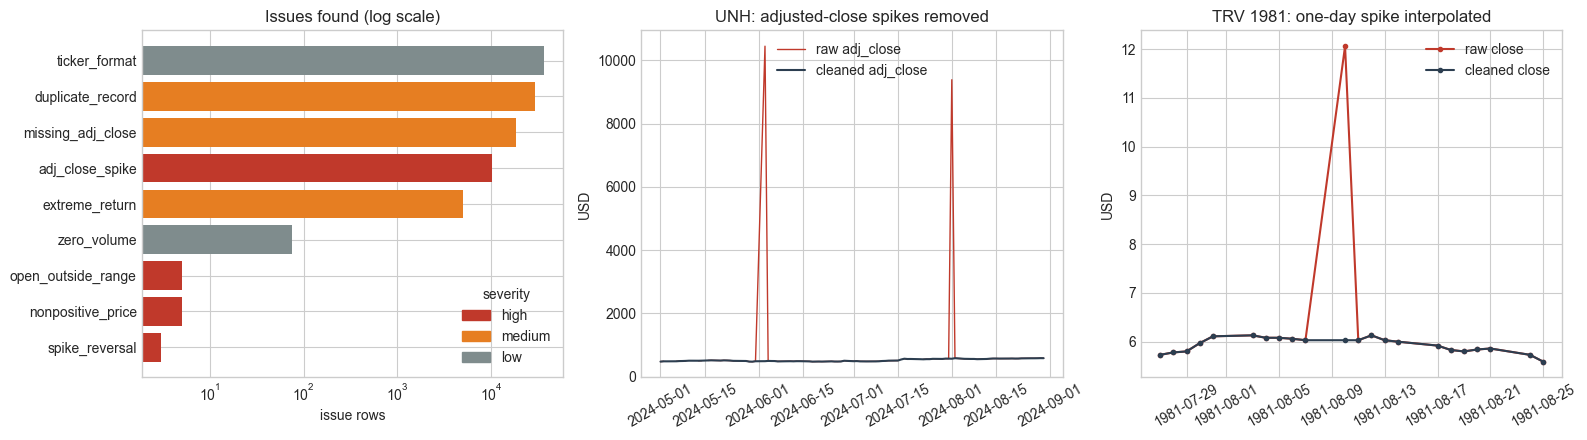

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

colors = {'high': '#c0392b', 'medium': '#e67e22', 'low': '#7f8c8d'}
counts = summary.sort_values('issues')
axes[0].barh(counts['issue_type'], counts['issues'], color=counts['severity'].map(colors))
axes[0].set_xscale('log')
axes[0].set_title('Issues found (log scale)')
axes[0].set_xlabel('issue rows')
axes[0].legend(handles=[Patch(color=color, label=severity) for severity, color in colors.items()],
               title='severity', loc='lower right')

window = ('2024-05-01', '2024-08-31')
before = records[(records['ticker'] == 'UNH') & records['ts'].between(*window)]
after = cleaned[(cleaned['ticker'] == 'UNH') & cleaned['ts'].between(*window)]
axes[1].plot(pd.to_datetime(before['ts']), before['adj_close'], color='#c0392b', lw=1, label='raw adj_close')
axes[1].plot(pd.to_datetime(after['ts']), after['adj_close'], color='#2c3e50', lw=1.5, label='cleaned adj_close')
axes[1].set_title('UNH: adjusted-close spikes removed')
axes[1].set_ylabel('USD')
axes[1].legend()

window = ('1981-07-27', '1981-08-25')
before = records[(records['ticker'] == 'TRV') & records['ts'].between(*window)]
after = cleaned[(cleaned['ticker'] == 'TRV') & cleaned['ts'].between(*window)]
axes[2].plot(pd.to_datetime(before['ts']), before['close'], 'o-', color='#c0392b', ms=3, label='raw close')
axes[2].plot(pd.to_datetime(after['ts']), after['close'], 'o-', color='#2c3e50', ms=3, label='cleaned close')
axes[2].set_title('TRV 1981: one-day spike interpolated')
axes[2].set_ylabel('USD')
axes[2].legend()

for ax in axes[1:]:
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout()
plt.show()

## Save to the database

The following tables are written to the **local working copy**, `data/data.db`:

| Table | Contents |
|---|---|
| `ohlc_hw_cleaned` | the cleaned data plus repair and flag columns. A unique index on `(ticker, ts)` keeps the keys unique and speeds up Part 2's per-ticker queries. |
| `ohlc_hw_quarantine` | each quarantined row in its original form, with the reason |
| `ohlc_hw_quality_report` | the pre-repair Data Quality Report |
| `ohlc_hw_ticker_audit` | every raw ticker label and the ticker it was normalized to |

The raw `ohlc_hw` table is left untouched, and the last cell checks that.

In [28]:
cleaned.to_sql('ohlc_hw_cleaned', conn, if_exists='replace', index=False)
conn.execute('CREATE UNIQUE INDEX IF NOT EXISTS idx_ohlc_hw_cleaned_ticker_ts ON ohlc_hw_cleaned (ticker, ts)')
quarantine.to_sql('ohlc_hw_quarantine', conn, if_exists='replace', index=False)
quality_report.assign(issue_date=quality_report['issue_date'].dt.strftime('%Y-%m-%d')).to_sql(
    'ohlc_hw_quality_report', conn, if_exists='replace', index=False)
ticker_audit.to_sql('ohlc_hw_ticker_audit', conn, if_exists='replace', index=False)
conn.commit()

saved = pd.read_sql_query('SELECT COUNT(*) AS n, COUNT(DISTINCT ticker) AS tickers FROM ohlc_hw_cleaned', conn)
assert saved.loc[0, 'n'] == len(cleaned)
sample = pd.read_sql_query(
    "SELECT ts, ticker, close, adj_close FROM ohlc_hw_cleaned "
    "WHERE ticker = ? AND ts BETWEEN ? AND ? ORDER BY ts LIMIT 5", conn, params=('AAPL', '2024-01-01', '2024-12-31'))
print(f"ohlc_hw_cleaned saved: {saved.loc[0, 'n']:,} rows, {saved.loc[0, 'tickers']} tickers. SQL date filter check:")
display(sample)

raw_after = pd.read_sql_query('SELECT * FROM ohlc_hw', conn)
assert pd.util.hash_pandas_object(raw_after, index=False).sum() == raw_fingerprint, 'raw table changed!'
print('Raw ohlc_hw table verified unchanged.')
conn.close()

ohlc_hw_cleaned saved: 368,246 rows, 30 tickers. SQL date filter check:


,ts,ticker,close,adj_close
0,2024-01-02,AAPL,185.64,184.94
1,2024-01-03,AAPL,184.25,183.55
2,2024-01-04,AAPL,181.91,181.22
3,2024-01-05,AAPL,181.18,180.50
4,2024-01-08,AAPL,185.56,184.86


Raw ohlc_hw table verified unchanged.


## Summary of decisions

| Issue | Found | Decision |
|---|---|---|
| HTML markup in ticker labels | 120 of 150 labels | normalized before grouping; every label kept in `ohlc_hw_ticker_audit` |
| Exact duplicate records | 29,460 extra copies | removed; `n_raw_copies` records how many copies existed |
| Conflicting duplicates | 0 | the detector works (injected example); all versions would be quarantined |
| Missing trading days | 0 | checked against each ticker's reference calendar; reported, never filled |
| Missing raw prices / volume | 0 | forward-fill / 0 with a flag (injected example) |
| `open = 0` on a ticker's first day | 5 rows | **quarantined**: a leading gap with no earlier price to carry forward |
| Inflated adjusted close (4–24×) | 10,417 | rebuilt from the trusted reference factor × raw close |
| Missing adjusted close | 18,374 (after dedup) | 18,373 rebuilt from the trusted reference factor × raw close; 1 (on a repaired TRV spike day) from agreeing neighbour factors |
| One-day spike that reverses the next day | 3 (TRV) | confirmed errors; interpolated between valid neighbours |
| Other extreme returns (3σ) | ~5,000 | kept as genuine moves; `extreme_return_flag = 1` (MCD 1968 noted as a possible unadjusted split) |
| Zero volume | 75 | kept; `zero_volume_flag = 1` |

Run order: run this notebook first. It recreates `ohlc_hw_cleaned` from the raw table every time it runs.